# Buscar elementos por texto y ordenarlos

Pedidos de comercio electrónico de ejemplo — Camilo Fuentes

Busca pedidos por el texto de su categoría y compara sus importes con impuestos.

[Volver al índice](00_indice.ipynb)

## 1. Conexión

En Kibana (`http://localhost:5601`), la consola de Dev Tools envía peticiones a Elasticsearch. Python hace la misma petición directamente, sin pasar por Kibana: desde Jupyter en Docker Compose, `elasticsearch` es el nombre del servicio y `9200` su puerto. Si el kernel corre en el equipo anfitrión, usa `http://localhost:9200`.

El índice de ejemplo debe existir antes de ejecutar la consulta. Este cuaderno no instala datos ni modifica el clúster.

In [5]:
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt

url_elasticsearch = "http://elasticsearch:9200"

## 2. Configuración

El índice `kibana_sample_data_ecommerce` contiene pedidos. `match` analiza el texto de `category`; con `operator: and` exige todos los términos analizados, no una frase exacta. `sort` ordena por `taxful_total_price` (importe con impuestos). `size` limita los pedidos devueltos.

Edita estos valores para cambiar la consulta de Python.

In [6]:
indice = "kibana_sample_data_ecommerce"
termino = "clothing"
orden = "desc"
limite = 10

cuerpo = {
    "size": limite,
    "_source": ["order_id", "category", "taxful_total_price", "currency"],
    "query": {"match": {"category": {"query": termino, "operator": "and"}}},
    "sort": [{"taxful_total_price": {"order": orden}}],
}

## 3. Ejecución

Copia el bloque entero en la consola de Dev Tools para ejecutar la consulta con los valores predeterminados.

```http
GET kibana_sample_data_ecommerce/_search
{
  "size": 10,
  "_source": [
    "order_id",
    "category",
    "taxful_total_price",
    "currency"
  ],
  "query": {
    "match": {
      "category": {
        "query": "clothing",
        "operator": "and"
      }
    }
  },
  "sort": [
    {
      "taxful_total_price": {
        "order": "desc"
      }
    }
  ]
}
```

En Jupyter, ejecuta la siguiente celda. Imprime la URL y el JSON efectivos antes de enviar la petición de solo lectura.

In [7]:
url = f"{url_elasticsearch.rstrip('/')}/{indice}/_search"
cuerpo_json = json.dumps(cuerpo, ensure_ascii=False, indent=2)
print(f"GET {url}")
print(cuerpo_json)

solicitud = Request(
    url,
    data=cuerpo_json.encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="GET",
)

resultado = None
try:
    with urlopen(solicitud, timeout=10) as respuesta:
        resultado = json.load(respuesta)
except HTTPError as error:
    if error.code == 404:
        print(f"No se encontró el índice {indice}. Comprueba que el conjunto de ejemplo esté disponible.")
    else:
        print(f"Elasticsearch respondió con el código HTTP {error.code}. Revisa el índice y la consulta.")
except (URLError, TimeoutError):
    print("No se pudo conectar con Elasticsearch. Revisa la URL y el estado del servicio.")

GET http://elasticsearch:9200/kibana_sample_data_ecommerce/_search
{
  "size": 10,
  "_source": [
    "order_id",
    "category",
    "taxful_total_price",
    "currency"
  ],
  "query": {
    "match": {
      "category": {
        "query": "clothing",
        "operator": "and"
      }
    }
  },
  "sort": [
    {
      "taxful_total_price": {
        "order": "desc"
      }
    }
  ]
}


## 4. Visualización

Cada barra representa un pedido. La gráfica conserva el orden de la respuesta de arriba abajo; comprueba que los importes siguen el sentido elegido.

Pedido 739290: Men's Clothing
Pedido 718360: Men's Clothing, Men's Shoes, Men's Accessories
Pedido 714566: Men's Clothing, Men's Shoes, Women's Accessories
Pedido 731279: Women's Clothing, Women's Shoes
Pedido 724489: Women's Clothing, Women's Shoes, Women's Accessories
Pedido 713508: Men's Clothing, Men's Shoes, Men's Accessories
Pedido 719568: Men's Clothing, Men's Shoes, Men's Accessories
Pedido 719317: Men's Clothing
Pedido 721778: Men's Shoes, Men's Clothing
Pedido 718552: Men's Clothing, Men's Shoes


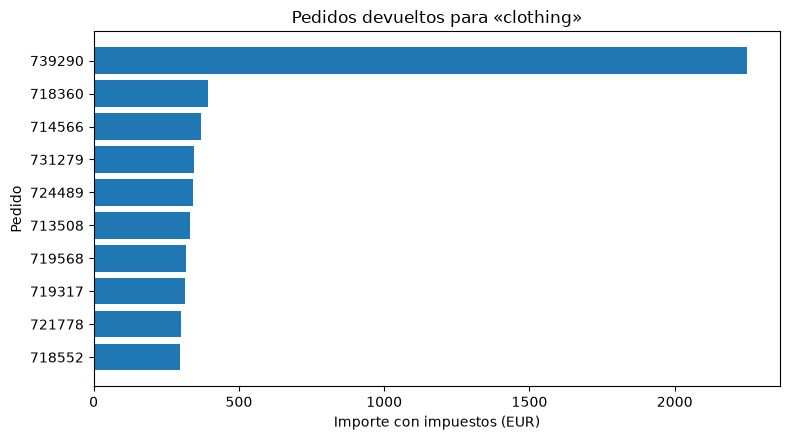

In [8]:
if resultado is not None:
    pedidos = [hit["_source"] for hit in resultado["hits"]["hits"]]
    if not pedidos:
        print("No se encontraron pedidos para el texto indicado.")
    else:
        for pedido in pedidos:
            categorias = ", ".join(pedido["category"])
            print(f'Pedido {pedido["order_id"]}: {categorias}')

        etiquetas = [str(pedido["order_id"]) for pedido in pedidos]
        importes = [pedido["taxful_total_price"] for pedido in pedidos]
        monedas = ", ".join(sorted({pedido["currency"] for pedido in pedidos}))
        fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(pedidos) + 1)))
        ax.barh(range(len(pedidos)), importes)
        ax.set_yticks(range(len(pedidos)), etiquetas)
        ax.invert_yaxis()
        ax.set(xlabel=f"Importe con impuestos ({monedas})", ylabel="Pedido",
               title=f'Pedidos devueltos para «{termino}»')
        fig.tight_layout()
        plt.show()